In [1]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

from src.config import *

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow 2.15.1 | GPUs: []


In [3]:
# Load images straight from the folders. Labels are one-hot, in MASK_CLASSES order.
def load_split(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path,
        labels="inferred",
        label_mode="categorical",
        class_names=MASK_CLASSES,
        image_size=MASK_IMG_SIZE,
        batch_size=MASK_BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_ds = load_split(MASK_TRAIN_DIR, shuffle=True)
val_ds = load_split(MASK_VAL_DIR, shuffle=False)
test_ds = load_split(MASK_TEST_DIR, shuffle=False)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Class weights: rare classes get a bigger weight so the model does not ignore them
counts = np.array([len(list((MASK_TRAIN_DIR / c).glob("*"))) for c in MASK_CLASSES])
weights = counts.sum() / (len(counts) * counts)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print("train images per class:", dict(zip(MASK_CLASSES, counts.tolist())))
print("class weights:", {MASK_CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

Found 1564 files belonging to 3 classes.
Found 350 files belonging to 3 classes.
Found 338 files belonging to 3 classes.
train images per class: {'mask_weared_incorrect': 56, 'with_mask': 1288, 'without_mask': 220}
class weights: {'mask_weared_incorrect': 9.31, 'with_mask': 0.4, 'without_mask': 2.37}


In [4]:
def build_cnn():
    inputs = keras.Input(shape=(*MASK_IMG_SIZE, 3))

    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(1.0 / 255)(x)

    for filters in (32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(MASK_CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mask_cnn")


model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()



Model: "mask_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 random_flip (RandomFlip)    (None, 224, 224, 3)       0         
                                                                 
 random_rotation (RandomRot  (None, 224, 224, 3)       0         
 ation)                                                          
                                                                 
 random_zoom (RandomZoom)    (None, 224, 224, 3)       0         
                                                                 
 rescaling (Rescaling)       (None, 224, 224, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 224, 224, 32)      896       
                                                        

In [5]:
def plot_history(histories, title):
    acc = sum([h.history["accuracy"] for h in histories], [])
    val_acc = sum([h.history["val_accuracy"] for h in histories], [])
    loss = sum([h.history["loss"] for h in histories], [])
    val_loss = sum([h.history["val_loss"] for h in histories], [])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(acc, label="train"); axes[0].plot(val_acc, label="val"); axes[0].set_title(title + " - accuracy"); axes[0].legend()
    axes[1].plot(loss, label="train"); axes[1].plot(val_loss, label="val"); axes[1].set_title(title + " - loss"); axes[1].legend()
    plt.tight_layout(); plt.show()


def evaluate_model(model, ds, show=True):
    # ds must NOT be shuffled, so predictions line up with labels
    y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in ds])
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    if show:
        labels = list(range(len(MASK_CLASSES)))
        print(classification_report(y_true, y_pred, labels=labels, target_names=MASK_CLASSES, digits=3, zero_division=0))
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=labels),
                               display_labels=MASK_CLASSES).plot(cmap="Blues", xticks_rotation=25)
        plt.show()
    return y_true, y_pred

Epoch 1/30


49/49 [==============================] - 47s 850ms/step - loss: 0.9655 - accuracy: 0.5601 - val_loss: 1.3962 - val_accuracy: 0.1086 - lr: 0.0010
Epoch 2/30
49/49 [==============================] - 40s 805ms/step - loss: 0.9741 - accuracy: 0.5972 - val_loss: 1.5599 - val_accuracy: 0.1629 - lr: 0.0010
Epoch 3/30
49/49 [==============================] - 37s 749ms/step - loss: 0.8846 - accuracy: 0.6311 - val_loss: 2.0859 - val_accuracy: 0.1657 - lr: 0.0010
Epoch 4/30
49/49 [==============================] - ETA: 0s - loss: 0.8683 - accuracy: 0.6400
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
49/49 [==============================] - 38s 775ms/step - loss: 0.8683 - accuracy: 0.6400 - val_loss: 1.8020 - val_accuracy: 0.2800 - lr: 0.0010
Epoch 5/30
49/49 [==============================] - 39s 800ms/step - loss: 0.7960 - accuracy: 0.6650 - val_loss: 2.2566 - val_accuracy: 0.1714 - lr: 5.0000e-04
Epoch 6/30
49/49 [==============================] - 42s

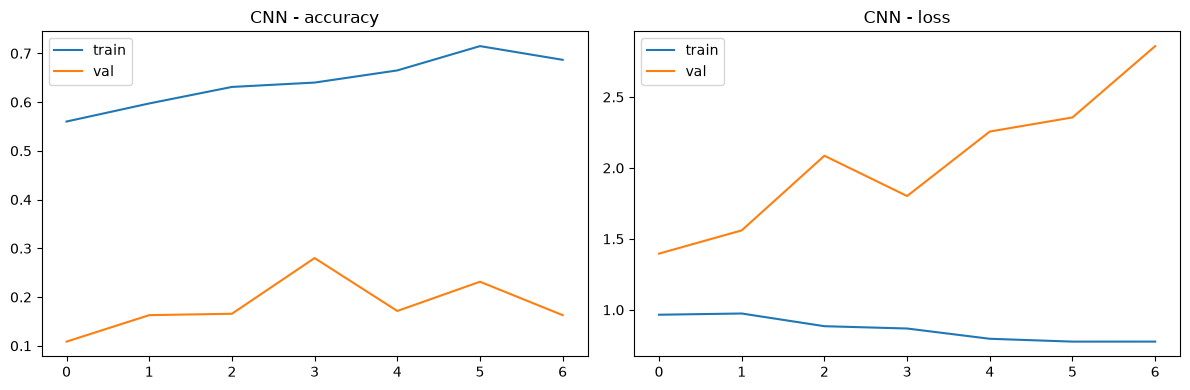

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=30,
                    class_weight=class_weight, callbacks=callbacks)
plot_history([history], "CNN")

                       precision    recall  f1-score   support

mask_weared_incorrect      0.056     0.615     0.103        13
            with_mask      0.000     0.000     0.000       285
         without_mask      0.113     0.550     0.187        40

             accuracy                          0.089       338
            macro avg      0.056     0.388     0.097       338
         weighted avg      0.016     0.089     0.026       338



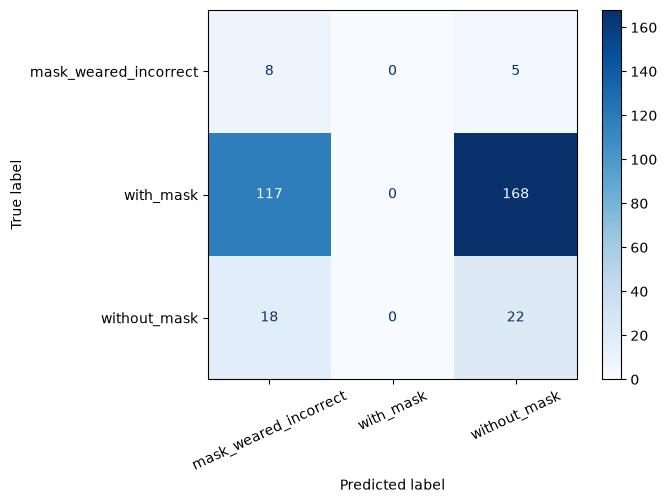

Test accuracy: 0.0888 | macro F1: 0.0966


In [7]:
y_true, y_pred = evaluate_model(model, test_ds)
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4),
      "| macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

In [8]:
model.save(MASK_CNN_PATH)
print("Saved:", MASK_CNN_PATH)

# Reload and run through the same preprocessing that the API will use
from src.mask_detection import preprocess_faces

reloaded = keras.models.load_model(MASK_CNN_PATH, compile=False)
sample_path = next((MASK_TEST_DIR / "with_mask").glob("*.jpg"))
probs = reloaded.predict(preprocess_faces([cv2.imread(str(sample_path))]), verbose=0)[0]
print(sample_path.name, "->", MASK_CLASSES[int(np.argmax(probs))], dict(zip(MASK_CLASSES, probs.round(3))))

Saved: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\mask_cnn.keras
maksssksksss103_0.jpg -> without_mask {'mask_weared_incorrect': 0.328, 'with_mask': 0.186, 'without_mask': 0.485}
